# Notebook 1 — PDF Text Extraction and Exploratory Data Analysis

**Project:** Research Paper Intelligence Assistant  
**Run in:** Google Colab  

This notebook uploads research-paper PDFs, extracts page-by-page text, creates a clean table of pages, calculates document statistics, shows charts, and lets you download the extracted text as CSV.

**Limitations:** text-based PDFs work best. Scanned PDFs may produce little or no text because this notebook does not run OCR. Your files are processed in this Colab session; do not upload confidential papers unless you are comfortable using Colab.

In [1]:
# Install the PDF reader and analysis libraries.
!pip -q install pymupdf pandas matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 57.3 MB/s eta 0:00:00


## 1. Import libraries

Libraries are tools we reuse instead of writing everything from scratch.

In [2]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
import fitz  # PyMuPDF: reads text from PDF files
from google.colab import files
from IPython.display import display

print("Libraries are ready.")


Libraries are ready.


## 2. Upload your research papers

Click **Choose Files** and select one or more PDF files from your computer.

In [4]:
uploaded = files.upload()
pdf_paths = [name for name in uploaded.keys() if name.lower().endswith(".pdf")]
csv_paths = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not pdf_paths and not csv_paths:
    raise ValueError("No PDF or CSV uploaded. Run this cell again and select at least one .pdf or .csv file.")

print(f"Uploaded {len(pdf_paths)} PDF file(s) and {len(csv_paths)} CSV file(s):")
for path in pdf_paths + csv_paths:
    print("-", path)

Saving arXiv_scientific_dataset.csv to arXiv_scientific_dataset (1).csv
Uploaded 0 PDF file(s) and 1 CSV file(s):
- arXiv_scientific_dataset (1).csv


## 3. Extract text from each page

We store one row per page so results can point back to the page where the text was found.

In [6]:
def clean_text(text):
    """Normalize whitespace while preserving readable text."""
    if not isinstance(text, str):
        return ""
    text = text.replace("\x00", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

page_records = []
file_errors = []

# Handle PDF files
for pdf_path in pdf_paths:
    try:
        with fitz.open(pdf_path) as pdf:
            for page_index, page in enumerate(pdf):
                text = clean_text(page.get_text("text"))
                page_records.append({
                    "paper": Path(pdf_path).name,
                    "page": page_index + 1,
                    "text": text,
                    "word_count": len(text.split()),
                    "character_count": len(text),
                })
    except Exception as exc:
        file_errors.append((pdf_path, str(exc)))

# Handle CSV files
for csv_path in csv_paths:
    try:
        df_temp = pd.read_csv(csv_path)
        # Detect potential text columns
        text_col = next((col for col in ["text", "summary", "abstract", "content"] if col in df_temp.columns), None)
        if not text_col:
            # Fallback to the first string column
            text_col = df_temp.select_dtypes(include=["object"]).columns[0]

        for index, row in df_temp.iterrows():
            raw_text = str(row[text_col]) if text_col in df_temp.columns else ""
            cleaned = clean_text(raw_text)
            page_records.append({
                "paper": Path(csv_path).name,
                "page": index + 1,
                "text": cleaned,
                "word_count": len(cleaned.split()),
                "character_count": len(cleaned),
            })
    except Exception as exc:
        file_errors.append((csv_path, str(exc)))

pages_df = pd.DataFrame(page_records)
if pages_df.empty:
    raise ValueError("No text data could be extracted or read from the uploaded files.")

display(pages_df[["paper", "page", "word_count", "character_count"]].head(10))
print(f"\nExtracted/Loaded {len(pages_df)} record(s) from {pages_df["paper"].nunique()} file(s).")
if file_errors:
    print("\nFiles that could not be read:")
    for name, error in file_errors:
        print(f"- {name}: {error}")

,paper,page,word_count,character_count
0,arXiv_scientific_dataset (1).csv,1,79,545
1,arXiv_scientific_dataset (1).csv,2,119,876
2,arXiv_scientific_dataset (1).csv,3,167,1075
3,arXiv_scientific_dataset (1).csv,4,174,1120
4,arXiv_scientific_dataset (1).csv,5,187,1289
5,arXiv_scientific_dataset (1).csv,6,161,1147
6,arXiv_scientific_dataset (1).csv,7,144,939
7,arXiv_scientific_dataset (1).csv,8,132,852
8,arXiv_scientific_dataset (1).csv,9,194,1389
9,arXiv_scientific_dataset (1).csv,10,130,823



Extracted/Loaded 287421 record(s) from 1 file(s).


## 4. Check for empty/scanned pages

Pages with zero extracted words might be blank or image-based scanned pages.

In [7]:
empty_pages = pages_df[pages_df["word_count"] == 0]
print(f"Pages with no selectable text: {len(empty_pages)}")
if len(empty_pages):
    display(empty_pages[["paper", "page"]].head(20))
    print("Tip: scanned pages usually require OCR, which is not included in this notebook.")


Pages with no selectable text: 0


## 5. Document-level summary table

In [8]:
document_summary = (
    pages_df.groupby("paper", as_index=False)
    .agg(
        pages=("page", "count"),
        total_words=("word_count", "sum"),
        total_characters=("character_count", "sum"),
        pages_without_text=("word_count", lambda values: int((values == 0).sum())),
    )
    .sort_values("total_words", ascending=False)
)

display(document_summary)


,paper,pages,total_words,total_characters,pages_without_text
0,arXiv_scientific_dataset (1).csv,287421,49138545,357093320,0


## 6. Plot words extracted per paper

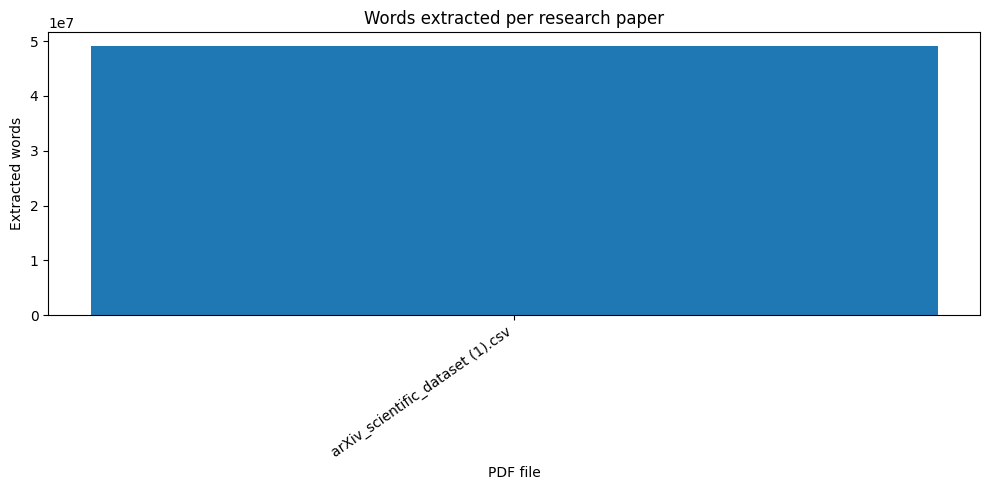

In [9]:
plt.figure(figsize=(10, 5))
plt.bar(document_summary["paper"], document_summary["total_words"])
plt.title("Words extracted per research paper")
plt.xlabel("PDF file")
plt.ylabel("Extracted words")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 7. Plot word counts page by page

Choose a paper from the dropdown by changing `selected_paper` below.

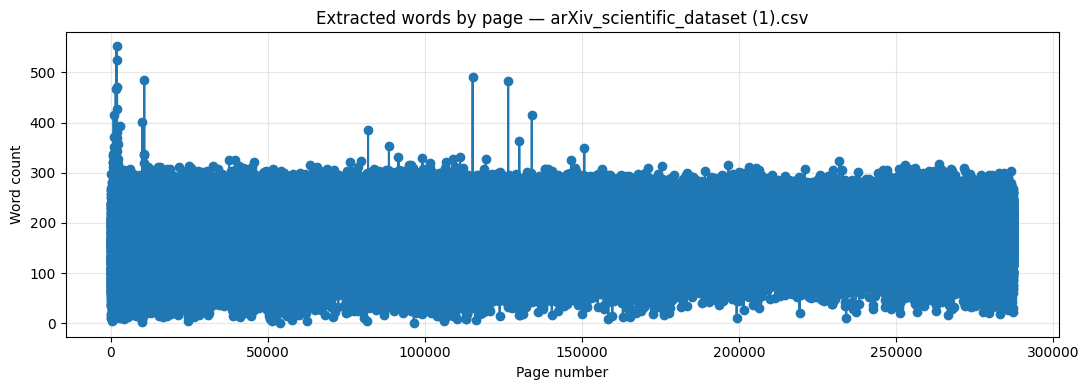

In [10]:
selected_paper = document_summary.iloc[0]["paper"]
paper_pages = pages_df[pages_df["paper"] == selected_paper].sort_values("page")

plt.figure(figsize=(11, 4))
plt.plot(paper_pages["page"], paper_pages["word_count"], marker="o")
plt.title(f"Extracted words by page — {selected_paper}")
plt.xlabel("Page number")
plt.ylabel("Word count")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Preview the text from a page

Edit the filename and page number to inspect a specific page.

In [11]:
preview_paper = pages_df.iloc[0]["paper"]
preview_page = int(pages_df.iloc[0]["page"])
row = pages_df[(pages_df["paper"] == preview_paper) & (pages_df["page"] == preview_page)]
print(f"Paper: {preview_paper} | Page: {preview_page}\n")
print(row.iloc[0]["text"][:5000] if not row.empty else "Page not found.")


Paper: arXiv_scientific_dataset (1).csv | Page: 1

Because of their occasional need to return to shallow points in a search
tree, existing backtracking methods can sometimes erase meaningful progress
toward solving a search problem. In this paper, we present a method by which
backtrack points can be moved deeper in the search space, thereby avoiding this
difficulty. The technique developed is a variant of dependency-directed
backtracking that uses only polynomial space while still providing useful
control information and retaining the completeness guarantees provided by
earlier approaches.


## 9. Download extracted text as CSV

The CSV contains one row per page with the paper name, page number, extracted text, and counts.

In [12]:
output_csv = "research_paper_pages.csv"
pages_df.to_csv(output_csv, index=False, encoding="utf-8-sig")
files.download(output_csv)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What you learned

- How PDF text extraction works with PyMuPDF.
- Why keeping page numbers helps create traceable search results.
- How to use Pandas for document-level statistics.
- How to spot PDFs that may need OCR.

**Next:** Open `02_search_and_summarization.ipynb` to search multiple papers and generate simple extractive summaries.